# Example 5.2: Error Surface in Design Space
**Chapter 5 · Formulation of the Synthesis Problem**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Fixing **c=75 mm** and **d=85 mm**, evaluate the Hausdorff error E(a,b) on a 12×12 point grid with:

- a ∈ [20, 100] mm
- b ∈ [60, 140] mm

Plot the **error surface** as a contour map and a heatmap. Identify the most promising design region (global minimum of the grid).

**Objective:** Visualize the multimodal complexity of the objective function E(x) and motivate the use of evolutionary algorithms over gradient-based methods.

In [1]:
from numpy import *
import matplotlib.pyplot as plt
import builtins

plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

# Save built-in max function before any overrides
builtin_max_fn = builtins.max

# ── Hausdorff function───────────────────────────────────────────────────
def hausdorff_fn(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any(): return 1e6
    D = sqrt((Cx[m,None]-Px[None,:])**2 + (Cy[m,None]-Py[None,:])**2)
    val1 = D.min(0).max()
    val2 = D.min(1).max()
    return builtin_max_fn(val1, val2)

def coupler52(a, b, c, d, p=35., delta=pi/5):
    th2 = linspace(0, 2*pi, 72)
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    A=cos(th2)-K1-K2*cos(th2)+K3; B=-2*sin(th2)
    C=K1-(K2+1)*cos(th2)+K3; disc=B**2-4*A*C
    K4=d/b; K5=(c**2-d**2-a**2-b**2)/(2*a*b)
    A2=cos(th2)-K1+K4*cos(th2)+K5; B2=-2*sin(th2)
    C2=K1+(K4-1)*cos(th2)+K5; disc2=B2**2-4*A2*C2
    th3=where(disc>=0,2*arctan2(-B2-sqrt(maximum(disc2,0)),2*A2),nan)
    return a*cos(th2)+p*cos(th3+delta), a*sin(th2)+p*sin(th3+delta)

# ── Desired trajectory────────────────────────────────────────────────────
t = linspace(0, 2*pi, 20)
Px = 45 + 22*cos(t); Py = 25 + 18*sin(t)

# ── 12×12 mesh───────────────────────────────────────────────────────────
c_fijo, d_fijo = 75., 85.
a_vals = linspace(20, 100, 12)
b_vals = linspace(60, 140, 12)
Z = zeros((12, 12))

for i, av in enumerate(a_vals):
    for j, bv in enumerate(b_vals):
        Cx_, Cy_ = coupler52(av, bv, c_fijo, d_fijo)
        Z[i, j] = hausdorff_fn(Cx_, Cy_, Px, Py)

i_min, j_min = unravel_index(Z.argmin(), Z.shape)
print(f"Minimum on grid: a = {a_vals[i_min]:.1f} mm, b = {b_vals[j_min]:.1f} mm")
print(f"Minimum error: {Z[i_min, j_min]:.2f} mm")
print(f"Maximum error: {Z[Z<1e5].max():.2f} mm")
print(f"Mean error:    {Z[Z<1e5].mean():.2f} mm")



Minimum on grid: a = 20.0 mm, b = 140.0 mm
Minimum error: 30.98 mm
Maximum error: 108.30 mm
Mean error:    69.78 mm


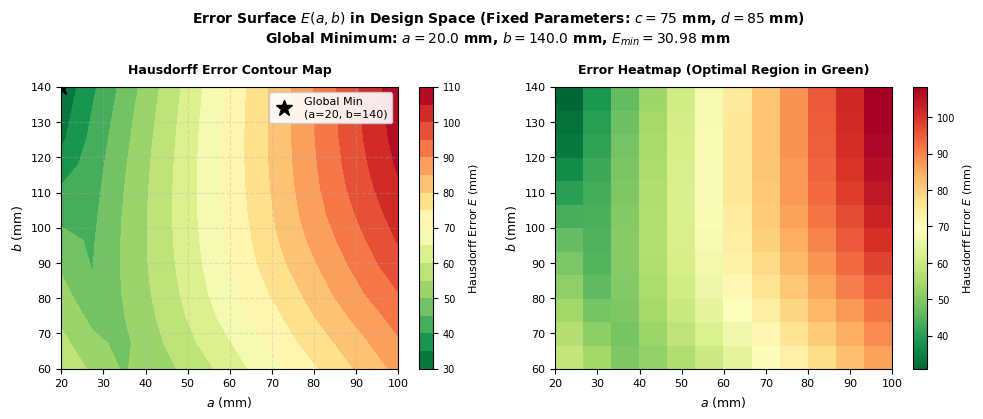

In [3]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# ── Automated Filename System ─────────────────────────────────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex5_2_error_surface_design_space"
except Exception:
    notebook_name = "ex5_2_error_surface_design_space"

# ── Springer Professional Plot Styling ────────────────────────────────────
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

Z_plot = np.clip(Z, 0, 200)
AA, BB = np.meshgrid(a_vals, b_vals, indexing='ij')

# Set physical dimension matching Springer guidelines for double subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# 1. Contour Plot
cs = axes[0].contourf(AA, BB, Z_plot, 15, cmap='RdYlGn_r')
cbar1 = plt.colorbar(cs, ax=axes[0])
cbar1.set_label('Hausdorff Error $E$ (mm)', fontsize=8)
cbar1.ax.tick_params(labelsize=7)

axes[0].set_xlabel('$a$ (mm)', fontsize=9)
axes[0].set_ylabel('$b$ (mm)', fontsize=9)
axes[0].set_title('Hausdorff Error Contour Map', fontsize=9, fontweight='bold', pad=10)
axes[0].grid(True, linestyle='--', alpha=0.3)

# Position the indicator clean and isolated from the text label
axes[0].plot(a_vals[i_min], b_vals[j_min], 'k*', ms=12,
             label=f'Global Min\n(a={a_vals[i_min]:.0f}, b={b_vals[j_min]:.0f})')
axes[0].legend(loc='upper right', framealpha=0.9)

# 2. Heatmap Plot
im = axes[1].imshow(Z_plot.T, origin='lower', aspect='auto',
                    extent=[a_vals[0], a_vals[-1], b_vals[0], b_vals[-1]],
                    cmap='RdYlGn_r')
cbar2 = plt.colorbar(im, ax=axes[1])
cbar2.set_label('Hausdorff Error $E$ (mm)', fontsize=8)
cbar2.ax.tick_params(labelsize=7)

axes[1].set_xlabel('$a$ (mm)', fontsize=9)
axes[1].set_ylabel('$b$ (mm)', fontsize=9)
axes[1].set_title('Error Heatmap (Optimal Region in Green)', fontsize=9, fontweight='bold', pad=10)

# Overall Figure Settings with Safe Margins
plt.suptitle(f'Error Surface $E(a, b)$ in Design Space (Fixed Parameters: $c=75$ mm, $d=85$ mm)\n'
             f'Global Minimum: $a={a_vals[i_min]:.1f}$ mm, $b={b_vals[j_min]:.1f}$ mm, '
             f'$E_{{min}}={Z[i_min,j_min]:.2f}$ mm',
             fontsize=10, fontweight='bold', y=0.98)

plt.tight_layout()

# ── Dual Format Mandatory Export ──────────────────────────────────────────
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()